<!-- **Notes on Python virtual environment**

To activate the virtual environment, fix Windows bug then activate:
1. `Set-ExecutionPolicy Unrestricted -Scope Process`
2. `.venv\Scripts\activate` -->

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
from algorithms import pgextra, nids, fast_pgextra, gen_fast_pgextra
import pickle

In [2]:
# Resolvent - soft thresholding operator
def soft_threshold(x, s):
    return np.sign(x) * np.clip(np.abs(x) - s, a_min=0, a_max=None) # Using numpy array operations

def JA(z, step, data):
    r"""
    Soft-thresholding operator: sgn(z[i])*max(abs(z[i])-\tau \lambda[i]), 0)
    """
    n = z.shape[0]
    JAz = np.zeros(z.shape)
    for ii in range(n):
        zi = z[ii].flatten()
        lambda_i = data['lambda'][ii]

        JAz[ii,:] = (1/n)*soft_threshold(zi, step*lambda_i)    
    
    return JAz

def B(z, data):
    r"""
    Evaulate operator B(z) = Mi^T@(Mi@z-yi)
    """
    n = z.shape[0]
    Bz = np.zeros(z.shape)

    for ii in range(n):
        zi = z[ii].flatten()
        Mi = data['M'][ii]
        yi = data['y'][ii]

        Bz[ii,:] = (1/n)*Mi.T@(Mi@zi - yi)
        
    return Bz

In [3]:
def residue_pg(x2, x1, K2, tW):
    r""" Distance between iterates, $||x^{k+1} - x^k}||^2_\tilde{W} + ||q^{k+1} - q^k}||^2$ where \tilde{W} = (I+W)/2
    :param: K2: K**2 = (I-W)/2
    :param: tW: = (I+W)/2
    """
    return np.vdot(x2, K2@x2) + np.vdot(x2 - x1, tW@(x2-x1))

def relerror_pg(x2, u1, q1, y2, step, tW, K2):
    """
    :param: x2: x^{k+1}
    :param: u1: u^{k}
    :param: q1: sum_{t=0}^k x^t
    :param: y2: B(x2)
    :param: tW: (I+W)/2
    :param: K2: K**2 = (I-W)/2
    """
    
    arg = step*y2 + u1 - x2 + K2@q1
    return  np.vdot(arg, tW@arg)

def consensus_pg(x2, K2):
    """
    :param: K2: K**2 = (I-W)/2
    """
    return np.vdot(x2, K2@x2)

def residue_fpg(z1, x1, tW, K2):
    r""" Distance between iterates, $||\bar{x}^{k} - x^k||^2_\tilde{W} + ||\bar{x}^k||^2_{K^2}$ 
    np.vdot is the Frobenius inner product, which is the usual inner product on vectorised matrices
    :param: tW: = (I+W)/2
    :param: K2: = (I-W)/2 = I - tW
    """
    return np.vdot(z1 - x1, tW@(z1-x1)) + np.vdot(z1, K2@z1)

def relerror_fpg(z1, gradf_z1, u1, q1, tW):
    r""" Optimality error, $||\tau \nabla f(\bar{x}^k) + \tau r^k + \tau Ky^k||^2_{(I+W)/2}$ where $r^k = (u^k-\bar{x}^k)/\tau$
    np.vdot is the Frobenius inner product, which is the usual inner product on vectorised matrices
    :param: gradf_z1: \nabla f(z1)
    :param: q1 = sum_{t=0}^k v^t
    :param: tW: = (I+W)/2
    """
    arg = tau*gradf_z1 + u1 - z1 + q1
    return np.vdot(arg,tW@arg)

def consensus_fpg(z1, K2):
    """
    :param: K2: K**2 = (I-W)/2
    """
    return np.vdot(z1, K2@z1)

def residue_nids(u2, u1, x1, tau, beta, tW):
    r""" Distance between iterates, $(1/\tau)||z^{k+1} - z^k}||^2 + ||d^{k+1} - d^k}||^2$ where \tilde{W} = (I+W)/2
    # Usig NIDS, Remark 3 to compute residue., \beta/2*(I - W) (xk - zk + zk+1)
    :param: tW: = ((I+W)/2)^2
    """
    return (1./tau)*np.linalg.norm(u2 - u1)**2 + np.linalg.norm(beta*tW@(x1 - u1 + u2))**2

def relerror_nids(x2, u1, q1, y2, step, tildeW, K2):
    """
    :param: x2: x^{k+1}
    :param: u1: u^{k}
    :param: q1: sum_{t=0}^k x^t
    :param: y2: B(x2)
    :param: K2: K**2 = (I-W)/2
    """
    
    arg = step*y2 + u1 - x2 + K2@q1
    return  np.vdot(arg, tildeW@arg)

def consensus_nids(x2, K2):
    """
    :param: K2: K**2 = (I-W)/2
    """
    return np.vdot(x2, K2@x2)

In [4]:
# rng_gen = np.random.default_rng(2026)
# nagents = 10
# p = 20
# mdim = [20]*nagents    # sensing matrix M is m[i] x p

# # Objective function parameters
# # M = {ii: rng_gen.normal(loc=0, scale=1, size=(mdim[ii], p)) for ii in range(nagents)} # Store M as dictionary to allow different m_i's
# # for ii in range(nagents):
# #     M[ii] /= np.linalg.norm(M[ii], ord=2)    # Normalise matrices
# M = {ii: random_matrix(p, rng_gen.uniform(low=0.5, high=1.5)) for ii in range(nagents)}

# e_vec = {ii: rng_gen.normal(loc=0, scale=0.1, size=mdim[ii]) for ii in range(nagents)}

# xstar = np.zeros(p) # signal
# xstar_nonzero = rng_gen.permutation(list(range(p)))[:int(0.2*p)] # generate 0.2p indices of xstar to make nonzero
# xstar[xstar_nonzero] = rng_gen.uniform(low=-1,high=1, size=xstar_nonzero.shape)

# y = np.array([M[ii]@xstar + e_vec[ii] for ii in range(nagents)])

# # Regularisation parameters
# lambda_vec = 0.005*np.ones(nagents)
# # lambda_vec = np.array([rng_gen.uniform(low=2.75, high=3.25) for ii in range(nagents)])
# datadict = {'M': M, 'y': y, 'lambda': lambda_vec}

# Mcond = [np.linalg.cond(M[ii]) for ii in range(nagents)]

In [5]:
nagents = 10
with open(r'C:\Users\TIMMSLF\OneDrive - The University of Melbourne\Documents\PhD\Code\Data_fast_pgextra\dict_of_lasso_instances', 'rb') as f:
    instance_dict = pickle.load(f)
datadict = instance_dict[0]

M = datadict['M']
p = M[0].shape[1]
Mcond = [np.linalg.cond(M[ii]) for ii in range(nagents)]

In [6]:
# Algorithm parameters
# Graph from PG-EXTRA
edges = [(0,1),(0,3),(0,4),(0,6),
         (1,6),
         (2,6),(2,8),
         (3,4),(3,6),(3,8),(3,9),
         (4,5),
         (5,8),(5,9),
         (6,7),(6,8),
         (7,9),
         (8,9)]
        
G = nx.Graph(edges)

# Laplacian-based constant edge weight matrix
# Lap = nx.laplacian_matrix(G).todense()  # Laplacian
# beta = 0.6 * np.max(np.linalg.eigvalsh(Lap))    # beta satisfies beta > lambda_max(Lap)/2
# W = np.eye(nagents) - Lap / beta

# Metropolis constant edge weight matrix
eps = 1.
W = np.zeros((nagents, nagents))
for i,j in edges:
    W[i,j] = 1./(max(G.degree[i], G.degree[j])+eps) # w_ij = 1/(max{d_i, d_j}+\eps) for i,j\in Edges
    W[j, i] = W[i,j]
for i in range(nagents):
    W[i,i] = 1. - np.sum(W[i,:])    # w_ii = 1 - \sum_{j\in Edges} w_ij


L = (1./nagents)*np.max([np.linalg.svdvals(M[ii])[0] for ii in range(nagents)])  # L = max_i L_i = max_i {(1/n)|Mi^T @ Mi|}
tau = 0.9 * (1 + np.min(np.linalg.eigvalsh(W))) / L  # tau <= (1-||K||^2)/L
thetainv = 2. - tau*L/(1 + np.min(np.linalg.eigvalsh(W)))   # 1/averaged constant of Condat-Vu operator
s = 0.9* thetainv # 0 < s < (4\beta_M-1)/(2\beta_M) # parameter for Fast PG-EXTRA
alpha = 5.  # parameter for Fast PG-EXTRA
beta = 0.9/np.linalg.norm(tau*0.5*(np.eye(nagents)-W), ord=2)   # parameter for NIDS, \beta = 1/||tau^(1/2)*((I-W)/2)*tau^(1/2))||
maxit = 10000

def alpha_k(k):
    r"""
    Linear cooling heuristic: alpha(k) increasing linearly to 100*\alpha at maxit/2 iterations. 
    \alpha_max = 100*\alpha
    :param: k: iteration number
    """
    if k<= (maxit//2):
        ak = alpha + 99*alpha*k/(maxit//2)
    else:
        ak = 100*alpha
    return ak

# def alpha_k(k):
#     r"""
#     Logarithmic cooling heuristic: alpha(k) increasing logarithmically to 100*\alpha at maxit/2 iterations. 
#     \alpha_max = 100*\alpha
#     :param: k: iteration number"""
#     if k <= (maxit//2):
#         a_exp = np.log(100)/(maxit//2 - 1) # Exponential coefficient: log(\alpha_max/\alpha_0)/(floor(maxit/2)-1)
#         ak = alpha*np.exp(a_exp*(k-1))
#     else:
#         ak = 100*alpha
#     return ak

def sigma_k(k):
    return alpha_k(k)

In [7]:
x0 = np.zeros((nagents, p))
# Run PG-EXTRA, NIDS, and (normal) Fast PG-EXTRA
zsol1, res_pg, rel_pg, con_pg = pgextra(x0, JA, B, W, tau, residue_pg, relerror_pg, consensus_pg, max_iters=maxit, data=datadict)
print()
zsol2, res_nids, rel_nids, con_nids = nids(x0, JA, B, W, tau, beta, residue_nids, relerror_nids, consensus_nids, max_iters=maxit, data=datadict)
# print()
# zsol3, res_fpg, rel_fpg, con_fpg = fast_pgextra(x0, JA, B, W, tau, alpha, s, residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)

etas = [0.95, 1.0] # [0.1, 0.5, 0.8, 0.95, 1.0]
num_params = len(etas)

res_gfpg = np.zeros((num_params, maxit))
rel_gfpg = np.zeros((num_params, maxit))
con_gfpg = np.zeros((num_params, maxit))

# Run Generalised Fast PG-EXTRA for different etas and linear cooling alpha(k)
for ii in range(num_params):
    print(f'\neta={etas[ii]:.2f}',end='\n')
    _, res_gfpg[ii,:], rel_gfpg[ii,:], con_gfpg[ii,:] = gen_fast_pgextra(x0, JA, B, W, tau, alpha_k, s, sigma_k, etas[ii], residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)
print('')

# Run Generalised Fast PG-EXTRA with alpha(k)=500
_, res_gfpg500, rel_gfpg500, con_gfpg500 = gen_fast_pgextra(x0, JA, B, W, tau, lambda k: 500, s, lambda k: 500, etas[ii], residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)


PG-EXTRA: iteration 10000 of 10000
NIDS: iteration 10000 of 10000
eta=0.95
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=1.00
Gen. Fast PG-EXTRA: iteration 10000 of 10000


In [10]:
print(p)
print(np.mean([np.count_nonzero(zsol2[ii]) for ii in range(nagents)]))

50
40.6


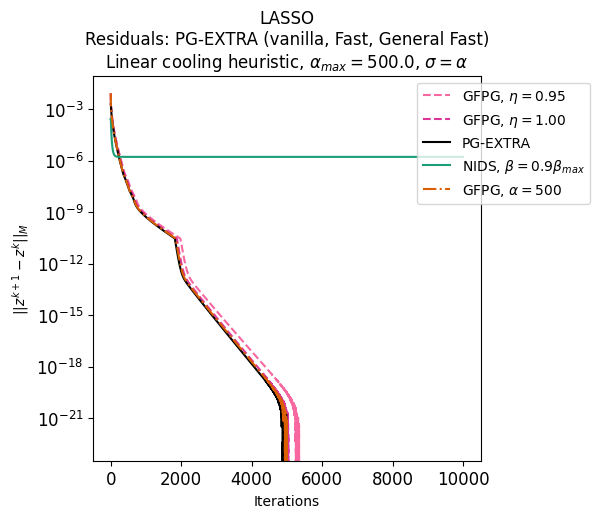

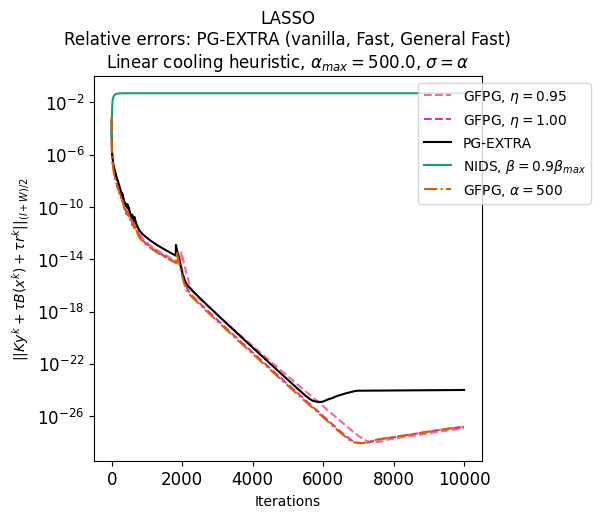

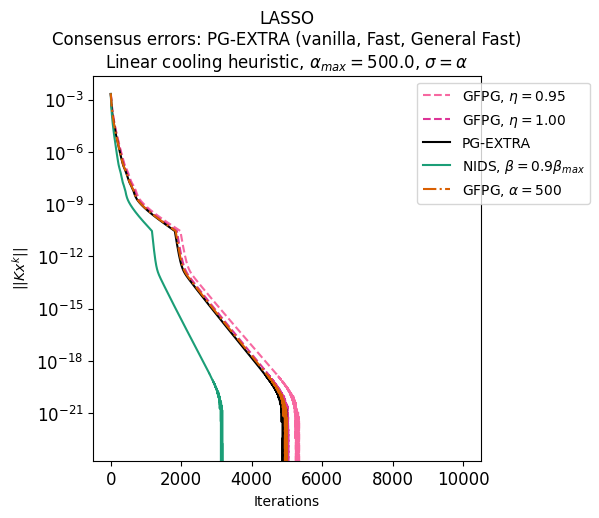

In [11]:
# 5-class sequential
colour = {'pg': 'k', 'nids': '#1b9e77', '500': '#d95f02', 0: '#f768a1', 1: '#dd3497', 2: '#ae017e', 3: '#7a0177', 4: '#49006a'}

# plasma = mpl.colormaps['plasma'].resampled(num_params)
# colour = {ii: plasma(ii) for ii in range(num_params)}
# colour['pg'] = 'k'
# colour['fpg']= 'r'

fig_res = plt.figure(figsize=(5, 5))
ax_res = fig_res.add_subplot(111)
scale_k = 1e-2
for ii in range(num_params):
    ax_res.semilogy(res_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_res.semilogy(res_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_res.semilogy(res_nids, color=colour['nids'], linestyle='-', label=r'NIDS, $\beta=0.9\beta_{max}$')
ax_res.semilogy(res_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
# ax_res.semilogy(res_fpg, color=colour['fpg'], linestyle='-.', label=r'FPG') # Fast PG-EXTRA (non-generalised)
ax_res.set_xlabel("Iterations")
ax_res.set_ylabel("$||z^{k+1}-z^k||_M$")
ax_res.set_title(f"LASSO\nResiduals: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_res.tick_params(axis='both', which='both', labelsize=12)
ax_res.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-5
fig_rel = plt.figure(figsize=(5, 5))
ax_rel = fig_rel.add_subplot(111)
for ii in range(num_params):
    ax_rel.semilogy(rel_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_rel.semilogy(rel_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_rel.semilogy(rel_nids, color=colour['nids'], linestyle='-', label=r'NIDS, $\beta=0.9\beta_{max}$')
ax_rel.semilogy(rel_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
# ax_rel.semilogy(rel_fpg, color=colour['fpg'], linestyle='-.', label=r'FPG') # Fast PG-EXTRA (non-generalised)
ax_rel.set_xlabel("Iterations")
ax_rel.set_ylabel(r"$||Ky^k + \tau B(x^k)+\tau r^k||_{(I+W)/2}$")
ax_rel.set_title(f"LASSO\nRelative errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_rel.tick_params(axis='both', which='both', labelsize=12)
ax_rel.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-2
scale_k2 = 1e-2
fig_con = plt.figure(figsize=(5, 5))
ax_con = fig_con.add_subplot(111)
for ii in range(num_params):
    ax_con.semilogy(con_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_con.semilogy(con_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_con.semilogy(con_nids, color=colour['nids'], linestyle='-', label=r'NIDS, $\beta=0.9\beta_{max}$')
ax_con.semilogy(con_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
# ax_con.semilogy(con_fpg, color=colour['fpg'], linestyle='-.', label=r'FPG') # Fast PG-EXTRA (non-generalised)
ax_con.set_xlabel("Iterations")
ax_con.set_ylabel(r"$||Kx^k||$")
ax_con.set_title(f"LASSO\nConsensus errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_con.tick_params(axis='both', which='both', labelsize=12)
ax_con.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

# filepath = r'C:\\Users\\TIMMSLF\\OneDrive - The University of Melbourne\\Documents\\PhD\\Code\\'
# fig_res.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_lasso_res.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_rel.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_lasso_rel.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_con.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_lasso_con.pdf', bbox_inches='tight', pad_inches=0.2)